<a href="https://colab.research.google.com/github/velezverespeter/energy-trading-risk/blob/main/notebooks/02_market_risk.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02 Market risk

This notebook measures the market risk of a 10 MW baseload position (240 MWh per day) in the Slovenian day-ahead market, using daily base prices for 2021–2025.

**Input:** `si_prices_daily.csv` (from notebook 01)
**Output:** `change_distribution.png`, `volatility.png`, `var_backtest.png`

When running in Google Colab, upload `si_prices_daily.csv` from the `data/` folder first.

## 1. Load daily prices

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

daily = pd.read_csv("si_prices_daily.csv", index_col=0, parse_dates=True)
print("Days:", len(daily))
daily.head()

Days: 1826


,base,peak
date,,
2021-01-01,46.405217,49.247500
2021-01-02,33.857917,NaN
2021-01-03,40.925000,NaN
2021-01-04,50.570000,61.125000
2021-01-05,57.294583,66.015833


## 2. Daily price changes

Changes are measured in EUR/MWh rather than percentages. Electricity prices can be close to zero or negative, which makes percentage returns meaningless, and absolute changes translate directly into profit and loss.

In [2]:
daily["change"] = daily["base"].diff()
daily["change"].describe()

count    1825.000000
mean        0.026861
std        33.218688
min      -161.223333
25%       -15.295000
50%        -2.036250
75%        10.970000
max       251.240000
Name: change, dtype: float64

## 3. Distribution of price changes

Most daily changes are small, but the distribution has fat tails: extreme moves occur far more often than a normal distribution would suggest.

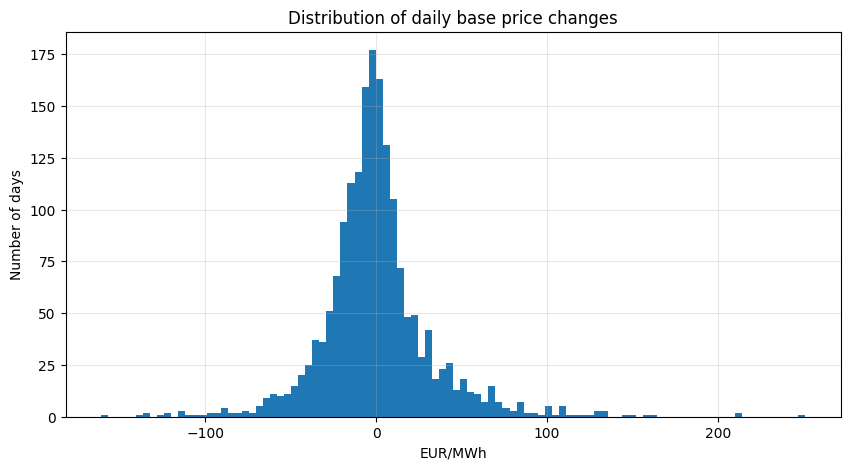

In [3]:
daily["change"].hist(bins=100, figsize=(10, 5))
plt.title("Distribution of daily base price changes")
plt.xlabel("EUR/MWh")
plt.ylabel("Number of days")
plt.grid(alpha=0.3)
plt.savefig("change_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Volatility over time

The 30-day rolling standard deviation of price changes shows how much calmer or more turbulent the market was in each period.

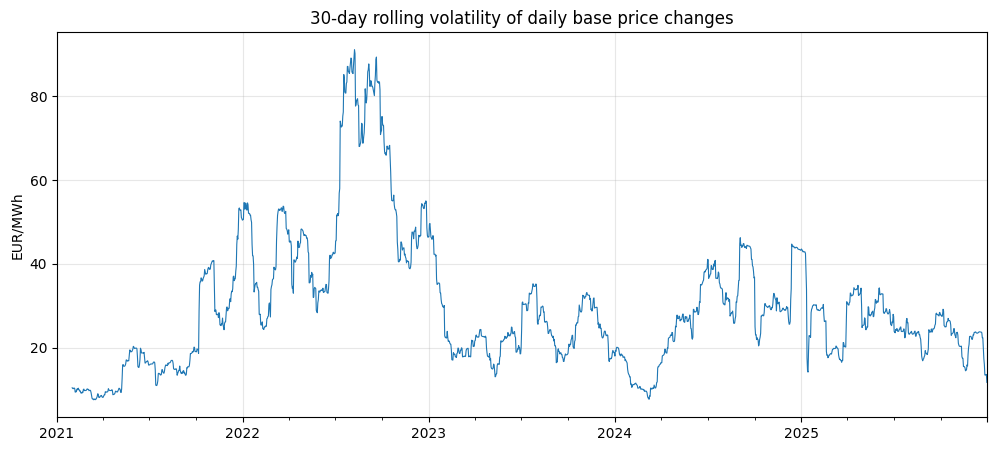

In [4]:
daily["volatility"] = daily["change"].rolling(30).std()

daily["volatility"].plot(figsize=(12, 5), linewidth=0.8)
plt.title("30-day rolling volatility of daily base price changes")
plt.ylabel("EUR/MWh")
plt.xlabel("")
plt.grid(alpha=0.3)
plt.savefig("volatility.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Value-at-Risk

The position is long 10 MW baseload, i.e. 240 MWh per day, so it loses money when prices fall. Daily profit and loss is 240 MWh × daily price change.

Historical VaR at 95% is the loss that was not exceeded on 95% of days. It is reported as a positive number.

In [5]:
position_mwh = 10 * 24

daily["pnl"] = position_mwh * daily["change"]

var_95 = -daily["pnl"].quantile(0.05)
var_99 = -daily["pnl"].quantile(0.01)

print(f"Daily VaR 95%: {var_95:,.0f} EUR")
print(f"Daily VaR 99%: {var_99:,.0f} EUR")

Daily VaR 95%: 10,881 EUR
Daily VaR 99%: 21,322 EUR


### VaR by year

In [6]:
var_by_year = -daily["pnl"].groupby(daily.index.year).quantile(0.05)
var_by_year.round(0)

date
2021     7787.0
2022    20036.0
2023     8780.0
2024     9195.0
2025     7904.0
Name: pnl, dtype: float64

### Historical vs. normal-distribution VaR

Under a normal distribution, 95% VaR equals 1.645 standard deviations and 99% VaR equals 2.326 standard deviations. Comparing these with historical VaR shows the effect of fat tails.

In [7]:
std = daily["pnl"].std()

print(f"Normal VaR 95%:     {1.645 * std:,.0f} EUR")
print(f"Historical VaR 95%: {var_95:,.0f} EUR")
print()
print(f"Normal VaR 99%:     {2.326 * std:,.0f} EUR")
print(f"Historical VaR 99%: {var_99:,.0f} EUR")

Normal VaR 95%:     13,115 EUR
Historical VaR 95%: 10,881 EUR

Normal VaR 99%:     18,544 EUR
Historical VaR 99%: 21,322 EUR


## 6. Backtesting

Each day, VaR is estimated from the previous 250 days only and compared with the actual result. Shifting the estimate by one day avoids look-ahead bias. A correct 95% VaR should be exceeded on about 5% of days.

In [8]:
window = 250  # roughly one year of observations

daily["var_95"] = -daily["pnl"].rolling(window).quantile(0.05).shift(1)
daily["exceedance"] = daily["pnl"] < -daily["var_95"]

test = daily.dropna(subset=["var_95"])
n_exceed = test["exceedance"].sum()
n_days = len(test)

print(f"Days tested:      {n_days}")
print(f"Exceedances:      {n_exceed}")
print(f"Exceedance rate:  {n_exceed / n_days:.1%} (expected 5%)")

Days tested:      1575
Exceedances:      101
Exceedance rate:  6.4% (expected 5%)


### Exceedances by year

In [9]:
by_year = test.groupby(test.index.year)["exceedance"].agg(["sum", "count", "mean"])
by_year.columns = ["exceedances", "days", "rate"]
by_year

,exceedances,days,rate
date,,,
2021,22,114,0.192982
2022,31,365,0.084932
2023,11,365,0.030137
2024,24,366,0.065574
2025,13,365,0.035616


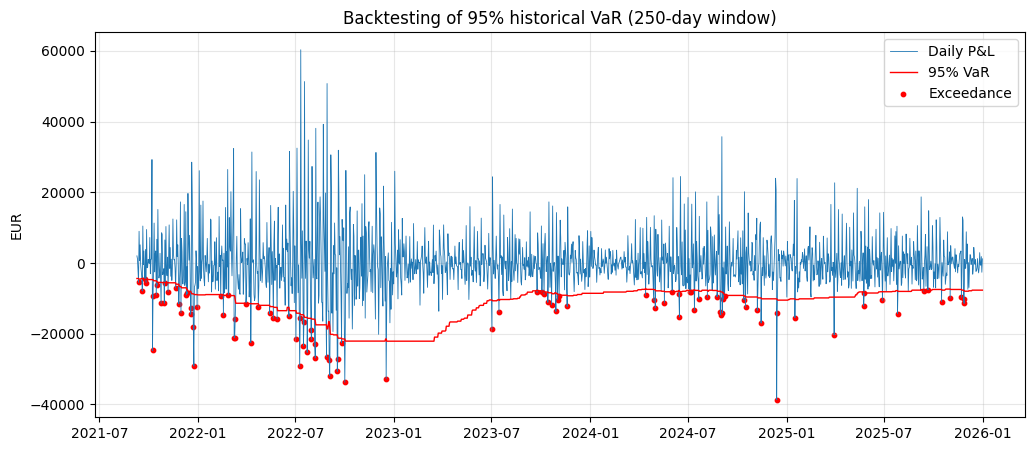

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(test.index, test["pnl"], linewidth=0.6, label="Daily P&L")
plt.plot(test.index, -test["var_95"], color="red", linewidth=1, label="95% VaR")
plt.scatter(test.index[test["exceedance"]], test["pnl"][test["exceedance"]],
            color="red", s=10, label="Exceedance")
plt.title("Backtesting of 95% historical VaR (250-day window)")
plt.ylabel("EUR")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("var_backtest.png", dpi=150, bbox_inches="tight")
plt.show()

Exceedances cluster in late 2021, when VaR was still based on calm months, and are rare in 2023, when the window still contained the 2022 crisis. VaR also jumps when extreme days leave the 250-day window (the "ghost effect").